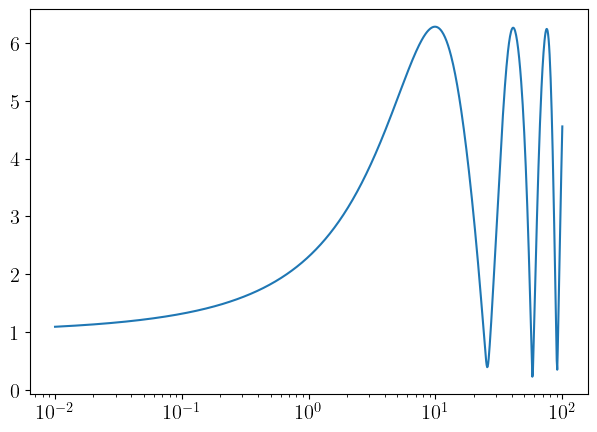

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from glow import lenses, time_domain_c, freq_domain_c
plotting.apply_figure_style()

ws = np.logspace(-2, 2, 1000)

#glow_nfw_Psi = lenses.Psi_NFW(p_phys={'name':'NFW','psi0':1.0,'xs':1/rs})
glow_cis_Psi = lenses.Psi_CIS()
glow_sis_Psi = lenses.Psi_SIS()
glow_pml_Psi = lenses.Psi_PointLens()



It =time_domain_c.It_SingleIntegral_C(glow_cis_Psi,y= 0.1)
Fw = freq_domain_c.Fw_FFT_C(It)
F = Fw(ws)

plt.semilogx(ws,np.abs(F))

GSL ERROR: maximum number of subdivisions reached [qag.c:257]


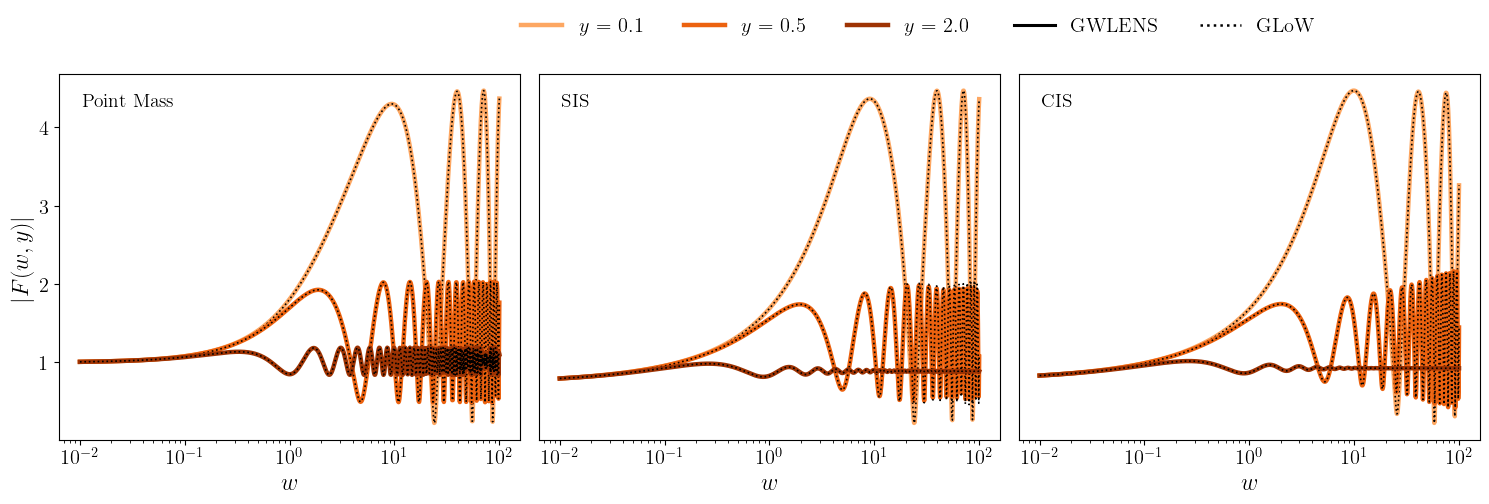

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens import solver1d
from gwlens.tools import plotting
from glow import lenses, time_domain_c, freq_domain_c

#Uncomment below if Latex works
plotting.apply_figure_style()
#plt.rcParams.update({'text.usetex': False})


glow_cmap = plt.get_cmap("BuPu")
gwlens_cmap = plt.get_cmap("Oranges")


ws = np.logspace(-2,2,1000)
y_values = [0.1,0.5,2.0]

colors = np.linspace(0.4, 0.9, len(y_values))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#GWLENS potentials
lens_pml = solver1d.point_mass()
lens_sis = solver1d.sis()
lens_cis = solver1d.cis()
lens_nfw = solver1d.nfw()
lens_powerlaw = solver1d.power_law()
#lens_plummer = solver1d.plummer()

#GLoW potentials
glow_cis_Psi = lenses.Psi_CIS()
glow_sis_Psi = lenses.Psi_SIS()
glow_pml_Psi = lenses.Psi_PointLens()

gwlens_lenses = [lens_pml, lens_sis, lens_cis]
glow_lenses = [glow_pml_Psi,glow_sis_Psi,glow_cis_Psi]
lens_names = ["Point Mass", "SIS", "CIS"]

for ax, gwlens_model,glow_model, lens_name in zip(axes,gwlens_lenses,glow_lenses,lens_names):

    for i,y_i in enumerate(y_values):

        #gwlens_evaluation
        F_gwlens = solver1d.amplification_many(ws,y_i,gwlens_model,n_workers=1)
        ax.semilogx(ws,np.abs(F_gwlens),label=f"$y$ = {y_i}",c=gwlens_cmap(colors[i]), linewidth=3.2)

        #glow_evaluation
        It =time_domain_c.It_SingleIntegral_C(glow_model,y= y_i)
        Fw = freq_domain_c.Fw_FFT_C(It)
        F_glow = Fw(ws)
        ax.semilogx(ws,np.abs(F_glow),c="black", linewidth=1.2, ls="dotted")
    
    # Add lens name inside the subplot
    ax.text( 0.05, 0.95, lens_name, transform=ax.transAxes, fontsize=14, fontweight="normal", ha="left", va="top" )
    #ax.legend()
    ax.set_xlabel('$w$')
    ax.set_ylabel('$|F(w,y)|$')

for ax in axes[1:]:
    ax.set_ylabel("")
    ax.tick_params(axis="y", left=False, labelleft=False)

method_handles = [
   Line2D([0], [0], color="black",linewidth=2.2, linestyle="-",label="GWLENS" ),
   Line2D( [0], [0], color="black",linewidth=1.8 , linestyle=":", label="GLoW" )]

fig.legend(
    handles=method_handles,
    loc="upper center",
    bbox_to_anchor=(0.78, 1.02),
    ncol=2,
    frameon=False)

# Create one shared legend using the first subplot's line labels
handles, labels = axes[0].get_legend_handles_labels()

fig.legend( handles, labels,  loc="upper center",  bbox_to_anchor=(0.5, 1.02), ncol=len(y_values), frameon=False)

# Adjust layout to leave room for the legend
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.savefig(fname="1dlens-comparison.png", dpi =300)
# Display the figure
plt.show()
